# Tugas Besar 2 IF3170: Prediksi Pembatalan Pemesanan Penginapan

# Initialization

## Import Libraries

In [1]:
import math
import heapq
import os
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed

## Settings

In [2]:
class Settings:
    SEED = 42
    N_FOLDS = 5
    N_JOBS = -1
    TARGET = 'is_canceled'
    ID_COLUMN = 'id'

    BASE_PARAMS = dict(criterion='gain_ratio', splitter='best', max_features=None, max_depth=30,
                       min_samples_split=2, min_samples_leaf=5, max_leaf_nodes=None,
                       min_impurity_decrease=2e-4, random_state=42)

    I = range(1, 101)
    SEARCH_SPACE = {
        'max_depth':             [i for i in I],
        'min_samples_split':     [max(2, i) for i in I],
        'min_samples_leaf':      [i for i in I],
        'max_leaf_nodes':        [5 * i for i in I],
        'min_impurity_decrease': [i * 1e-5 for i in I],
        'max_features':          [i / 100 for i in I],
    }
    CATEGORICAL_SPACE = {
        'criterion': ['gini', 'entropy', 'log_loss', 'gain_ratio'],
        'splitter':  ['best', 'random'],
    }

    N_RANDOM = 300
    TOP_CHECK = 5
    CHECK_SEEDS = [1, 2, 3, 4, 5]

    SUB_PATH = 'submission_dt_param_search.csv'

random.seed(Settings.SEED)
np.random.seed(Settings.SEED)
print('core CPU:', os.cpu_count())

core CPU: 14


## Load Dataset

In [3]:
train = pd.read_csv('train.csv', dtype={'id': str})
test = pd.read_csv('test.csv', dtype={'id': str})

pd.Series({'train': len(train), 'test': len(test)})

train    27373
test      6844
dtype: int64

# Kode Pendukung

## Preprocessing

In [4]:
# preprocessing bareng buat semua model: konstanta, cleaning, feature engineering, dan BasePreprocessor

TARGET = 'is_canceled'
ID_COL = 'id'
CAT_COLS = ['meal_package', 'room_category', 'booking_channel']

# buang row duplikat persis (feature dan target), khusus data train
def clean_train(df):
    feature_cols = [c for c in df.columns if c != ID_COL]
    return df.drop_duplicates(subset=feature_cols).reset_index(drop=True)

# nilai yang nggak masuk akal (num_adults = 0) dijadiin missing
def mark_invalid(df):
    df = df.copy()
    df.loc[df['num_adults'] == 0, 'num_adults'] = np.nan
    return df

# tambah feature turunan per row, aman dipakai di train dan test secara terpisah
def add_features(df):
    df = df.copy()
    df['total_nights'] = df['weekend_nights'] + df['weekday_nights']
    df['total_guests'] = df['num_adults'] + df['num_children']
    df['is_free'] = (df['nightly_rate_idr'] == 0).astype(float)
    df.loc[df['nightly_rate_idr'].isna(), 'is_free'] = np.nan
    df['rate_per_guest'] = df['nightly_rate_idr'] / df['total_guests'].replace(0, np.nan)

    arrival = pd.to_datetime(
        dict(year=df['arrival_year'], month=df['arrival_month'], day=df['arrival_day']),
        errors='coerce',
    )
    df['arrival_weekday'] = arrival.dt.day_of_week.astype(float)
    df['arrival_dayofyear'] = arrival.dt.day_of_year.astype(float)
    df['arrival_index'] = ((arrival - pd.Timestamp('2023-01-01')).dt.days).astype(float)
    return df

# base preprocessor semua model, statistiknya di-fit dari data train aja
# class turunan cukup override _fit_extra dan _transform_extra
class BasePreprocessor:

    # feature_engineering: pakai add_features atau nggak; rare_min_count: batas kategori langka
    def __init__(self, feature_engineering=True, rare_min_count=20, drop_cols=None):
        self.feature_engineering = feature_engineering
        self.rare_min_count = rare_min_count
        self.drop_cols = list(drop_cols or [])

    # fit kolom dan kategori dari data train, terus statistik khusus model
    def fit(self, df):
        df = self._base(df)
        self.cat_cols_ = [c for c in CAT_COLS if c in df.columns]
        self.num_cols_ = [c for c in df.columns if c not in self.cat_cols_]
        self.keep_cats_ = {}
        for c in self.cat_cols_:
            counts = df[c].value_counts()
            self.keep_cats_[c] = sorted(counts[counts >= self.rare_min_count].index)
        self._fit_extra(self._group_rare(df))
        return self

    # pakai transformasi yang udah di-fit ke data validasi atau test
    def transform(self, df):
        return self._transform_extra(self._group_rare(self._base(df)))

    # fit terus langsung transform
    def fit_transform(self, df):
        return self.fit(df).transform(df)

    # statistik khusus model, default-nya kosong
    def _fit_extra(self, df):
        pass

    # transformasi khusus model, default-nya data dibalikin apa adanya
    def _transform_extra(self, df):
        return df

    # tandai nilai aneh, tambah feature turunan (opsional), buang kolom id dan target
    def _base(self, df):
        df = mark_invalid(df)
        if self.feature_engineering:
            df = add_features(df)
        drop = [ID_COL, TARGET] + self.drop_cols
        return df.drop(columns=[c for c in drop if c in df.columns])

    # kategori yang nggak ada di daftar train diganti jadi 'Other'
    def _group_rare(self, df):
        df = df.copy()
        for c in self.cat_cols_:
            known = df[c].isin(self.keep_cats_[c]) | df[c].isna()
            df.loc[~known, c] = 'Other'
        return df

In [5]:
# preprocessor buat Decision Tree

# default: NaN dan kategori teks dibiarin karena tree bisa handle langsung, nggak perlu scaling
# impute_num: None, 'median', 'mean', atau 'mode' buat kolom numerik
# impute_cat: None atau 'mode' buat kolom kategorikal
# statistik imputasi di-fit dari data train, termasuk feature hasil engineering
class TreePreprocessor(BasePreprocessor):

    def __init__(self, impute_num=None, impute_cat=None, **kwargs):
        super().__init__(**kwargs)
        self.impute_num = impute_num
        self.impute_cat = impute_cat

    # simpan nilai pengisi per kolom dari data train
    def _fit_extra(self, df):
        self.fill_ = {}
        if self.impute_num is not None:
            for c in self.num_cols_:
                col = df[c]
                if self.impute_num == 'median':
                    self.fill_[c] = col.median()
                elif self.impute_num == 'mean':
                    self.fill_[c] = col.mean()
                else:
                    self.fill_[c] = col.mode()[0]
        if self.impute_cat == 'mode':
            for c in self.cat_cols_:
                self.fill_[c] = df[c].mode()[0]

    # isi missing value pakai nilai dari data train
    def _transform_extra(self, df):
        fill = getattr(self, 'fill_', {})
        return df.fillna(fill) if fill else df

## Validasi

In [6]:
# confusion matrix biner, bentuknya [[TN, FP], [FN, TP]]
def confusion_matrix(y_true, y_pred):
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    return np.array([[tn, fp], [fn, tp]])

# F1 buat class 0 dan class 1, hasilnya [f1_0, f1_1]
def f1_per_class(y_true, y_pred):
    (tn, fp), (fn, tp) = confusion_matrix(y_true, y_pred)
    f1_pos = 2 * tp / (2 * tp + fp + fn) if tp + fp + fn > 0 else 0.0
    f1_neg = 2 * tn / (2 * tn + fn + fp) if tn + fn + fp > 0 else 0.0
    return np.array([f1_neg, f1_pos])

# Macro F1, rata-rata F1 dua class (metric kompetisi)
def macro_f1(y_true, y_pred):
    return float(f1_per_class(y_true, y_pred).mean())

# cari threshold dengan Macro F1 paling tinggi, dipakai di prediksi out-of-fold
def best_threshold(y_true, proba, grid=None):
    if grid is None:
        grid = np.round(np.arange(0.20, 0.81, 0.01), 2)
    scores = np.array([macro_f1(y_true, (proba >= t).astype(int)) for t in grid])
    i = int(np.argmax(scores))
    return float(grid[i]), float(scores[i])

# bagi index jadi k fold dengan proporsi class yang sama, hasilnya list (train_idx, val_idx)
def stratified_kfold(y, n_splits=5, seed=42):
    y = np.asarray(y)
    rng = np.random.RandomState(seed)
    fold_of = np.empty(len(y), dtype=int)
    for c in np.unique(y):
        idx = np.where(y == c)[0]
        rng.shuffle(idx)
        fold_of[idx] = np.arange(len(idx)) % n_splits
    return [(np.where(fold_of != k)[0], np.where(fold_of == k)[0]) for k in range(n_splits)]

# cross validation yang balikin probabilitas out-of-fold
# preprocessor di-fit ulang tiap fold, cuma pakai data train fold itu
def cross_val_proba(make_model, make_prep, df, y, folds):
    y = np.asarray(y)
    oof = np.zeros(len(y))
    for tr_idx, va_idx in folds:
        prep = make_prep()
        X_tr = prep.fit_transform(df.iloc[tr_idx])
        X_va = prep.transform(df.iloc[va_idx])
        model = make_model()
        model.fit(X_tr, y[tr_idx])
        oof[va_idx] = model.predict_proba(X_va)
    return oof

# Macro F1 per fold dengan satu threshold, buat liat model stabil atau nggak
def fold_scores(y, proba, folds, threshold):
    y = np.asarray(y)
    pred = (proba >= threshold).astype(int)
    return np.array([macro_f1(y[va], pred[va]) for _, va in folds])

## Decision Tree from Scratch

In [7]:
# Decision Tree Learning (CART) from scratch buat klasifikasi biner

# satu node di tree, leaf cuma pakai value (proporsi class 1) dan n_samples
class Node:
    __slots__ = ('feature', 'threshold', 'is_cat', 'left_cats', 'seen_cats',
                 'missing_left', 'frac_left', 'left', 'right', 'value', 'n_samples', 'n_pos', 'gain')

    # bikin node dengan proporsi class 1 dan jumlah sample-nya
    def __init__(self, value, n_samples):
        self.value = value
        self.n_samples = n_samples
        self.n_pos = None
        self.feature = None
        self.threshold = None
        self.is_cat = False
        self.left_cats = None
        self.seen_cats = None
        self.missing_left = True
        self.frac_left = None
        self.left = None
        self.right = None
        self.gain = 0.0

    # True kalau node nggak punya child
    @property
    def is_leaf(self):
        return self.left is None

# impurity gini atau entropy (log_loss = entropy), dihitung vectorized dari jumlah positif dan total sample
def _impurity(pos, n, criterion):
    n = np.asarray(n, dtype=float)
    p = np.divide(pos, n, out=np.zeros_like(n), where=n > 0)
    if criterion == 'gini':
        return 2.0 * p * (1.0 - p)
    # entropy biner, dengan anggapan 0 * log(0) = 0
    q = 1.0 - p
    with np.errstate(divide='ignore', invalid='ignore'):
        h = -(np.where(p > 0, p * np.log2(p), 0.0) + np.where(q > 0, q * np.log2(q), 0.0))
    return h

# p-value uji chi-square (df = 1) buat tabel 2x2 branch kiri/kanan x class 0/1
def _chi2_p_value(nl, pl, nr, pr):
    n, pos = nl + nr, pl + pr
    denom = nl * nr * pos * (n - pos)
    if denom == 0:
        return 1.0
    chi2 = n * (pl * (nr - pr) - pr * (nl - pl)) ** 2 / denom
    # distribusi chi-square df 1: P(X > x) = erfc(sqrt(x / 2))
    return math.erfc(math.sqrt(chi2 / 2.0))

# nilai dengan total weight paling besar (nilai paling sering)
def _weighted_mode(x, w):
    vals, inv = np.unique(x, return_inverse=True)
    return vals[int(np.argmax(np.bincount(inv, weights=w)))]

# CART biner: split numerik pakai threshold, kategori diurutkan dari proporsi class 1,
# missing value di-handle sesuai parameter missing (default: ke branch yang impurity-nya paling kecil)
class DecisionTree:
    # criterion: 'gini', 'entropy', 'log_loss' (= entropy), atau 'gain_ratio' (C4.5)
    # splitter: 'best' (split point terbaik) atau 'random' (satu split point acak per feature, terus pilih feature terbaik)
    # max_features: jumlah feature yang dicoba per node. None (semua), int, float (fraksi), 'sqrt', atau 'log2'
    # min_samples_split, min_samples_leaf: int (jumlah sample) atau float (fraksi dari jumlah data train)
    # max_leaf_nodes: kalau diisi, tree tumbuh best-first (split dengan penurunan impurity terbesar duluan)
    # sampai jumlah leaf mencapai nilai ini
    # random_state: seed buat splitter 'random' dan max_features
    # min_impurity_decrease: penurunan impurity (weighted) minimum biar split diterima
    # max_p_value: kalau diisi, split cuma dibuat kalau p-value uji chi-square <= nilai ini
    # missing: cara handle missing value pas split
    # 'default'         : missing masuk ke branch yang impurity-nya paling kecil
    # 'node_mode'       : missing diisi nilai paling sering muncul di node
    # 'node_mode_class' : pas training, diisi nilai paling sering di node untuk class yang sama;
    # pas prediksi class-nya belum tahu, jadi pakai nilai paling sering di node
    # 'fractional'      : cara C4.5, gain dikali proporsi data yang nggak missing, terus yang missing dibagi
    # ke dua branch dengan weight pecahan
    # class_weight: None, 'balanced', atau angka weight class 1 relatif ke class 0
    # m_estimate: smoothing probabilitas leaf, (pos + m * prior) / (n + m); 0 artinya tanpa smoothing
    # ccp_alpha: kalau > 0, tree di-prune pakai cost-complexity pruning setelah dibangun
    def __init__(self, criterion='gini', max_depth=None, min_samples_split=2,
                 min_samples_leaf=1, min_impurity_decrease=0.0, max_p_value=None,
                 missing='default', class_weight=None, m_estimate=0.0, ccp_alpha=0.0,
                 splitter='best', max_features=None, max_leaf_nodes=None, random_state=None):
        self.criterion = criterion
        self.splitter = splitter
        self.max_features = max_features
        self.max_leaf_nodes = max_leaf_nodes
        self.random_state = random_state
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.min_impurity_decrease = min_impurity_decrease
        self.max_p_value = max_p_value
        self.missing = missing
        self.class_weight = class_weight
        self.m_estimate = m_estimate
        self.ccp_alpha = ccp_alpha

    # train tree, kolom teks di X dianggap kategorikal
    def fit(self, X, y):
        X = pd.DataFrame(X)
        self.feature_names_ = list(X.columns)
        self.is_cat_ = np.array([not pd.api.types.is_numeric_dtype(X[c]) for c in X.columns])
        # mapping kategori ke kode integer, di-fit dari data train
        self.cat_maps_ = {}
        for j, c in enumerate(self.feature_names_):
            if self.is_cat_[j]:
                cats = sorted(X[c].dropna().unique())
                self.cat_maps_[c] = {v: i for i, v in enumerate(cats)}

        self._X = self._to_array(X)
        self._y = np.asarray(y).astype(int)
        self.n_total_ = len(self._y)
        self.feature_importances_ = np.zeros(len(self.feature_names_))

        # weight awal per row: semua 1, atau class weight yang dinormalisasi biar totalnya tetap n
        w = np.ones(self.n_total_)
        if self.class_weight is not None:
            n_pos = self._y.sum()
            w1 = ((self.n_total_ - n_pos) / n_pos if self.class_weight == 'balanced'
                  else float(self.class_weight))
            w[self._y == 1] = w1
            w *= self.n_total_ / w.sum()
        self.prior_ = float(w @ self._y) / self.n_total_

        # parameter float dibaca sebagai fraksi dari jumlah data train
        frac = lambda v: math.ceil(v * self.n_total_) if isinstance(v, float) else v
        self._min_split = frac(self.min_samples_split)
        self._min_leaf = frac(self.min_samples_leaf)
        self._n_feat = self._resolve_max_features(len(self.feature_names_))
        self._rng = np.random.default_rng(getattr(self, 'random_state', None))

        if getattr(self, 'max_leaf_nodes', None) is None:
            self.root_ = self._build(np.arange(self.n_total_), w, depth=0)
        else:
            self.root_ = self._build_best_first(np.arange(self.n_total_), w)

        total = self.feature_importances_.sum()
        if total > 0:
            self.feature_importances_ /= total
        del self._X, self._y, self._rng
        if self.ccp_alpha > 0:
            self.cost_complexity_prune(self.ccp_alpha)
        return self

    # ubah DataFrame jadi array float: kategori jadi kode, missing jadi NaN, kategori baru jadi -2
    def _to_array(self, X):
        out = np.empty((len(X), len(self.feature_names_)), dtype=float)
        for j, c in enumerate(self.feature_names_):
            if self.is_cat_[j]:
                # kategori yang nggak ada pas train dikasih kode -2
                codes = X[c].map(self.cat_maps_[c])
                codes = codes.where(X[c].isna() | codes.notna(), -2)
                out[:, j] = codes.astype(float).to_numpy()
            else:
                out[:, j] = pd.to_numeric(X[c], errors='coerce').to_numpy(dtype=float)
        return out

    # jumlah feature yang dicoba per node, sesuai max_features
    def _resolve_max_features(self, n_features):
        mf = getattr(self, 'max_features', None)
        if mf is None:
            return n_features
        if mf == 'sqrt':
            return max(1, int(math.sqrt(n_features)))
        if mf == 'log2':
            return max(1, int(math.log2(n_features)))
        if isinstance(mf, float):
            return max(1, min(n_features, int(mf * n_features)))
        return max(1, min(n_features, int(mf)))

    # bangun tree secara rekursif (depth-first) dari row idx dengan weight w
    def _build(self, idx, w, depth):
        node = self._make_node(idx, w)
        split = self._find_split(node, idx, w, depth)
        if split is None:
            return node
        (idx_l, w_l), (idx_r, w_r) = self._apply_split(node, split)
        node.left = self._build(idx_l, w_l, depth + 1)
        node.right = self._build(idx_r, w_r, depth + 1)
        return node

    # bangun tree best-first: node yang penurunan impurity-nya paling besar di-split duluan,
    # stop kalau jumlah leaf udah sampai max_leaf_nodes
    def _build_best_first(self, idx, w):
        root = self._make_node(idx, w)
        heap, order, n_leaves = [], 0, 1

        def push(node, idx, w, depth):
            nonlocal order
            split = self._find_split(node, idx, w, depth)
            if split is not None:
                heapq.heappush(heap, (-split['weighted_gain'], order, node, split, depth))
                order += 1

        push(root, idx, w, 0)
        while heap and n_leaves < self.max_leaf_nodes:
            _, _, node, split, depth = heapq.heappop(heap)
            (idx_l, w_l), (idx_r, w_r) = self._apply_split(node, split)
            node.left, node.right = self._make_node(idx_l, w_l), self._make_node(idx_r, w_r)
            n_leaves += 1
            push(node.left, idx_l, w_l, depth + 1)
            push(node.right, idx_r, w_r, depth + 1)
        return root

    # bikin leaf dari row idx: proporsi class 1 (pakai m-estimate kalau diisi)
    def _make_node(self, idx, w):
        y = self._y[idx]
        n, pos = float(w.sum()), float(w @ y)
        m = getattr(self, 'm_estimate', 0.0)
        value = pos / n if m == 0 else (pos + m * self.prior_) / (n + m)
        node = Node(value=value, n_samples=int(n) if n == int(n) else n)
        node.n_pos = pos
        return node

    # cari split buat node, None kalau node harus jadi leaf (kena pre-pruning atau nggak ada split valid)
    def _find_split(self, node, idx, w, depth):
        y = self._y[idx]
        n, pos = float(w.sum()), float(w @ y)

        # kondisi stop (pre-pruning)
        if (pos == 0 or pos == n
                or n < self._min_split
                or n < 2 * self._min_leaf
                or (self.max_depth is not None and depth >= self.max_depth)):
            return None

        best = self._best_split(idx, y, w)
        if best is None:
            return None

        gain, f, thr, left_cats, seen_cats, miss_left, miss_by_class = best
        # penurunan impurity dibobot proporsi sample node terhadap semua data
        weighted_gain = gain * n / self.n_total_
        if weighted_gain < self.min_impurity_decrease:
            return None

        x, is_cat = self._X[idx, f], self.is_cat_[f]
        frac_left = None
        if self.missing == 'fractional':
            # row yang ada nilainya ikut kondisi split, row missing masuk ke dua branch
            unknown = np.isnan(x)
            known_left = ~unknown & self._cond(x, thr, left_cats, is_cat)
            frac_left = float(w[known_left].sum() / w[~unknown].sum())
            left_mask, right_mask = known_left | unknown, (~unknown & ~known_left) | unknown
            w_left = np.where(unknown, w * frac_left, w)[left_mask]
            w_right = np.where(unknown, w * (1.0 - frac_left), w)[right_mask]
        else:
            go_left = self._go_left(x, thr, left_cats, seen_cats, miss_left, is_cat)
            if miss_by_class is not None:
                # pas training, missing diarahkan sesuai nilai paling sering di class-nya
                go_left = np.where(np.isnan(x), np.where(y == 1, miss_by_class[1], miss_by_class[0]),
                                   go_left)
            left_mask, right_mask = go_left, ~go_left
            w_left, w_right = w[go_left], w[~go_left]

        if self.max_p_value is not None:
            nl, pl = float(w_left.sum()), float(w_left @ y[left_mask])
            if _chi2_p_value(nl, pl, n - nl, pos - pl) > self.max_p_value:
                return None
        return dict(gain=gain, weighted_gain=weighted_gain, feature=f, threshold=thr, is_cat=bool(is_cat),
                    left_cats=left_cats, seen_cats=seen_cats, missing_left=miss_left, frac_left=frac_left,
                    left=(idx[left_mask], w_left), right=(idx[right_mask], w_right))

    # simpan split di node, tambah feature importance, balikin (idx, w) branch kiri dan kanan
    def _apply_split(self, node, split):
        node.feature, node.threshold = split['feature'], split['threshold']
        node.is_cat = split['is_cat']
        node.left_cats, node.seen_cats = split['left_cats'], split['seen_cats']
        node.missing_left = split['missing_left']
        node.frac_left = split['frac_left']
        node.gain = split['gain']
        self.feature_importances_[split['feature']] += split['weighted_gain']
        return split['left'], split['right']

    # cari split terbaik dari semua feature, None kalau nggak ada split yang valid
    def _best_split(self, idx, y, w):
        n = float(w.sum())
        wy = w * y
        parent = _impurity(wy.sum(), n, self.criterion)
        best_gain, best = 1e-12, None
        candidates = []

        n_features = self._X.shape[1]
        features = (range(n_features) if self._n_feat >= n_features
                    else np.sort(self._rng.choice(n_features, self._n_feat, replace=False)))
        random_split = getattr(self, 'splitter', 'best') == 'random'

        for f in features:
            x = self._X[idx, f]
            miss = np.isnan(x)
            w_miss, pos_miss = float(w[miss].sum()), float(wy[miss].sum())
            xv, yv, wv = x[~miss], y[~miss], w[~miss]
            if len(xv) < 2:
                continue

            if self.is_cat_[f]:
                # urutkan kategori dari proporsi positif, terus ganti nilai x dengan ranking-nya
                cats, inv = np.unique(xv, return_inverse=True)
                if len(cats) < 2:
                    continue
                cnt = np.bincount(inv, weights=wv)
                pos_rate = np.bincount(inv, weights=wv * yv) / cnt
                order = np.argsort(pos_rate, kind='mergesort')
                rank = np.empty(len(cats), dtype=int)
                rank[order] = np.arange(len(cats))
                xv = rank[inv].astype(float)

            sort = np.argsort(xv, kind='mergesort')
            xs, ys, ws = xv[sort], yv[sort], wv[sort]
            # kandidat split point: cuma di antara dua nilai yang beda
            cut = np.where(xs[:-1] != xs[1:])[0]
            if len(cut) == 0:
                continue
            cum_w = np.cumsum(ws)
            cum_pos = np.cumsum(ws * ys)
            n_left = cum_w[cut]
            p_left = cum_pos[cut]
            w_known, pos_known = cum_w[-1], cum_pos[-1]
            # splitter random: cuma satu split point acak yang dinilai buat feature ini
            pick_cut = int(self._rng.integers(len(cut))) if random_split else None

            # tiap opsi: (missing class 0 ke kiri, missing class 1 ke kiri, arah missing pas prediksi)
            if self.missing == 'fractional':
                options = [None]
            elif self.missing in ('node_mode', 'node_mode_class'):
                mode_left = xs[cut] >= _weighted_mode(xs, ws)
                if self.missing == 'node_mode':
                    options = [(mode_left, mode_left, mode_left)]
                else:
                    # class yang nggak punya data non-missing pakai nilai paling sering di node
                    by_class = []
                    for c in (0, 1):
                        m = ys == c
                        by_class.append(xs[cut] >= _weighted_mode(xs[m], ws[m]) if m.any() else mode_left)
                    options = [(by_class[0], by_class[1], mode_left)]
            else:
                options = [(True, True, True), (False, False, False)] if w_miss > 0 else [(True, True, True)]

            for opt in options:
                if opt is None:
                    # C4.5: gain dihitung dari data yang nggak missing, terus dikali proporsinya
                    nl, pl = n_left, p_left
                    nr, pr = w_known - n_left, pos_known - p_left
                    valid = (nl >= self._min_leaf) & (nr >= self._min_leaf)
                    if pick_cut is not None:
                        valid = valid & (np.arange(len(valid)) == pick_cut)
                    if not valid.any():
                        continue
                    child = (nl * _impurity(pl, nl, self.criterion)
                             + nr * _impurity(pr, nr, self.criterion)) / w_known
                    known_parent = _impurity(pos_known, w_known, self.criterion)
                    gain = np.where(valid, (w_known / n) * (known_parent - child), -np.inf)
                    split_total = w_known
                    miss_pred = True
                else:
                    ml0, ml1, miss_pred = opt
                    nl = n_left + ml0 * (w_miss - pos_miss) + ml1 * pos_miss
                    pl = p_left + ml1 * pos_miss
                    nr = (w_known + w_miss) - nl
                    pr = (pos_known + pos_miss) - pl
                    valid = (nl >= self._min_leaf) & (nr >= self._min_leaf)
                    if pick_cut is not None:
                        valid = valid & (np.arange(len(valid)) == pick_cut)
                    if not valid.any():
                        continue
                    child = (nl * _impurity(pl, nl, self.criterion)
                             + nr * _impurity(pr, nr, self.criterion)) / n
                    gain = np.where(valid, parent - child, -np.inf)
                    split_total = n

                # hasil split buat split point ke-i
                def make_split(i, g):
                    pick = lambda v: bool(v[i]) if isinstance(v, np.ndarray) else bool(v)
                    miss_left = pick(miss_pred)
                    by_class = ((pick(opt[0]), pick(opt[1])) if self.missing == 'node_mode_class'
                                and opt is not None else None)
                    if self.is_cat_[f]:
                        # kategori dengan ranking <= split point masuk ke kiri
                        left_cats = cats[order[: int(xs[cut[i]]) + 1]]
                        return (g, f, None, left_cats, cats, miss_left, by_class)
                    thr = (xs[cut[i]] + xs[cut[i] + 1]) / 2.0
                    return (g, f, thr, None, None, miss_left, by_class)

                if self.criterion == 'gain_ratio':
                    # C4.5: gain ratio cuma buat split point yang gain-nya >= rata-rata gain
                    ok = gain > 1e-12
                    if not ok.any():
                        continue
                    ok &= gain >= gain[ok].mean() - 1e-12
                    split_info = _impurity(nl, np.full_like(nl, split_total), 'entropy')
                    ratio = np.where(ok, gain / np.maximum(split_info, 1e-12), -np.inf)
                    i = int(np.argmax(ratio))
                    candidates.append((float(ratio[i]), make_split(i, float(gain[i]))))
                    continue

                i = int(np.argmax(gain))
                if gain[i] > best_gain:
                    best_gain = float(gain[i])
                    best = make_split(i, best_gain)

        if self.criterion == 'gain_ratio' and candidates:
            # antar feature: pilih gain ratio terbesar dari feature yang gain-nya >= rata-rata
            avg_gain = np.mean([s[0] for _, s in candidates])
            ratio, best = max((c for c in candidates if c[1][0] >= avg_gain - 1e-12), key=lambda c: c[0])
        return best

    # tentuin row yang masuk branch kiri, missing dan kategori unknown ikut arah default
    @staticmethod
    def _go_left(x, thr, left_cats, seen_cats, miss_left, is_cat):
        if is_cat:
            # missing dan kategori yang belum pernah muncul di node ini ikut arah default
            unknown = np.isnan(x) | ~np.isin(x, seen_cats)
            return np.where(unknown, miss_left, np.isin(x, left_cats))
        return np.where(np.isnan(x), miss_left, x <= thr)

    # kondisi split buat nilai yang ada, True berarti masuk branch kiri
    @staticmethod
    def _cond(x, thr, left_cats, is_cat):
        if is_cat:
            return np.isin(x, left_cats)
        with np.errstate(invalid='ignore'):
            return x <= thr

    # reduced-error pruning dari bawah ke atas: subtree diganti leaf kalau error validasi nggak naik
    # label leaf pakai threshold (default 0.5 = class mayoritas)
    def prune(self, X_val, y_val, threshold=0.5):
        if getattr(self, 'missing', 'default') == 'fractional':
            raise NotImplementedError('prune belum mendukung missing fractional')
        Xa = self._to_array(pd.DataFrame(X_val))
        yv = np.asarray(y_val).astype(int)

        # balikin jumlah error validasi di subtree node setelah child-nya di-prune
        def visit(node, idx):
            leaf_err = int(np.sum(yv[idx] != int(node.value >= threshold)))
            if node.is_leaf:
                return leaf_err
            go_left = self._go_left(Xa[idx, node.feature], node.threshold, node.left_cats,
                                    node.seen_cats, node.missing_left, node.is_cat)
            sub_err = visit(node.left, idx[go_left]) + visit(node.right, idx[~go_left])
            if leaf_err <= sub_err:
                node.left = node.right = None
                node.feature = None
                return leaf_err
            return sub_err

        visit(self.root_, np.arange(len(yv)))
        self._recompute_importances()
        return self

    # cost-complexity pruning (CART): buat alpha tertentu, cari subtree dengan
    # R(T) + alpha * |leaf| paling kecil, R dihitung dari impurity leaf yang dibobot proporsi sample
    def cost_complexity_prune(self, alpha):
        crit = 'gini' if self.criterion == 'gini' else 'entropy'

        # balikin (R subtree terbaik, jumlah leaf) setelah child-nya di-prune
        def visit(node):
            r_leaf = node.n_samples / self.n_total_ * float(
                _impurity(node.n_pos, node.n_samples, crit))
            if node.is_leaf:
                return r_leaf, 1
            r_left, n_left = visit(node.left)
            r_right, n_right = visit(node.right)
            r_sub, n_sub = r_left + r_right, n_left + n_right
            if r_leaf + alpha <= r_sub + alpha * n_sub:
                node.left = node.right = None
                node.feature = None
                return r_leaf, 1
            return r_sub, n_sub

        visit(self.root_)
        self._recompute_importances()
        return self

    # hitung ulang feature importance dari split yang masih ada
    def _recompute_importances(self):
        imp = np.zeros(len(self.feature_names_))
        stack = [self.root_]
        while stack:
            node = stack.pop()
            if node.is_leaf:
                continue
            imp[node.feature] += node.gain * node.n_samples / self.n_total_
            stack += [node.left, node.right]
        total = imp.sum()
        self.feature_importances_ = imp / total if total > 0 else imp

    # probabilitas class 1 (proporsi class 1 di leaf) buat tiap row
    def predict_proba(self, X):
        Xa = self._to_array(pd.DataFrame(X))
        if getattr(self, 'missing', 'default') == 'fractional':
            return self._predict_fractional(Xa)
        out = np.empty(len(Xa))
        stack = [(self.root_, np.arange(len(Xa)))]
        while stack:
            node, idx = stack.pop()
            if node.is_leaf or len(idx) == 0:
                out[idx] = node.value
                continue
            go_left = self._go_left(Xa[idx, node.feature], node.threshold, node.left_cats,
                                    node.seen_cats, node.missing_left, node.is_cat)
            stack.append((node.left, idx[go_left]))
            stack.append((node.right, idx[~go_left]))
        return out

    # prediksi ala C4.5: row yang missing di node diterusin ke dua branch dengan weight frac_left,
    # hasilnya rata-rata weighted dari leaf yang dicapai
    def _predict_fractional(self, Xa):
        out = np.zeros(len(Xa))
        stack = [(self.root_, np.arange(len(Xa)), np.ones(len(Xa)))]
        while stack:
            node, idx, w = stack.pop()
            if len(idx) == 0:
                continue
            if node.is_leaf:
                out[idx] += w * node.value
                continue
            x = Xa[idx, node.feature]
            # missing dan kategori yang belum pernah muncul di node ini dianggap unknown
            unknown = np.isnan(x) | (~np.isin(x, node.seen_cats) if node.is_cat else False)
            left = ~unknown & self._cond(x, node.threshold, node.left_cats, node.is_cat)
            right = ~unknown & ~left
            stack.append((node.left, np.concatenate([idx[left], idx[unknown]]),
                          np.concatenate([w[left], w[unknown] * node.frac_left])))
            stack.append((node.right, np.concatenate([idx[right], idx[unknown]]),
                          np.concatenate([w[right], w[unknown] * (1.0 - node.frac_left)])))
        return out

    # label 0/1 berdasarkan threshold
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

    # depth tree hasil training
    def get_depth(self):
        def depth(node):
            return 0 if node.is_leaf else 1 + max(depth(node.left), depth(node.right))
        return depth(self.root_)

    # jumlah leaf di tree
    def get_n_leaves(self):
        def leaves(node):
            return 1 if node.is_leaf else leaves(node.left) + leaves(node.right)
        return leaves(self.root_)

    # teks kondisi split sebuah node, misal 'days_before_arrival <= 150.5'
    def describe_split(self, node):
        name = self.feature_names_[node.feature]
        if node.is_cat:
            inv = {v: k for k, v in self.cat_maps_[name].items()}
            cats = ', '.join(str(inv[int(c)]) for c in node.left_cats)
            return f'{name} in {{{cats}}}'
        return f'{name} <= {node.threshold:.4g}'

# Parameter Decision Tree

# Pencarian Parameter

## 4.1 Skema Validasi

In [8]:
train = clean_train(train)
y = train[Settings.TARGET].to_numpy()
folds = stratified_kfold(y, n_splits=Settings.N_FOLDS, seed=Settings.SEED)

def cv_score(params, folds=folds):
    oof = cross_val_proba(lambda: DecisionTree(**params), lambda: TreePreprocessor(), train, y, folds)
    threshold, score = best_threshold(y, oof)
    return score, threshold

def run_many(param_list, folds=folds):
    start = time.time()
    results = Parallel(n_jobs=Settings.N_JOBS)(delayed(cv_score)(p, folds) for p in param_list)
    print(f'{len(param_list)} run, waktu {time.time() - start:.0f} detik')
    rows = [{**p, 'oof_macro_f1': round(s, 4), 'threshold': t, 'params': p} for p, (s, t) in zip(param_list, results)]
    return pd.DataFrame(rows)

In [9]:
base_score, base_threshold = cv_score(Settings.BASE_PARAMS)
print('baseline OOF', round(base_score, 4), ' threshold', base_threshold)

baseline OOF 0.8343  threshold 0.51


## 4.2 Sapuan 1 sampai 100 per Parameter

In [10]:
def sweep(name, values):
    return run_many([Settings.BASE_PARAMS | {name: v} for v in values])

sweeps = {name: sweep(name, values) for name, values in Settings.SEARCH_SPACE.items()}

100 run, waktu 106 detik


100 run, waktu 108 detik


100 run, waktu 89 detik


100 run, waktu 104 detik


100 run, waktu 95 detik


100 run, waktu 65 detik


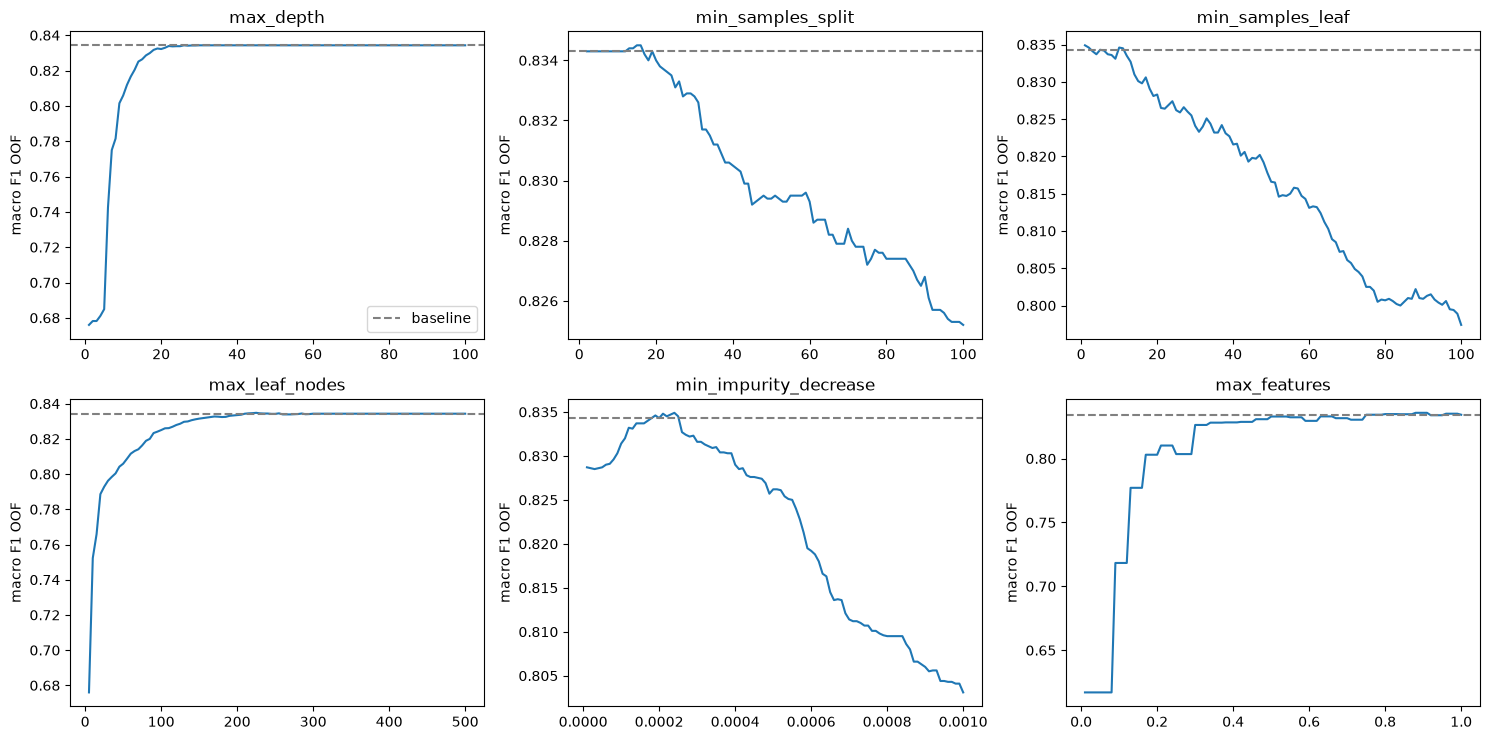

In [11]:
names = list(sweeps)
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for axis, name in zip(axes.flat, names):
    table = sweeps[name]
    axis.plot(table[name], table['oof_macro_f1'])
    axis.axhline(base_score, color='gray', linestyle='--', label='baseline')
    axis.set_title(name)
    axis.set_ylabel('macro F1 OOF')
axes.flat[0].legend()
plt.tight_layout()
plt.show()

In [12]:
best_per_param = pd.DataFrame([
    {'parameter': name, 'nilai_terbaik': t.loc[t['oof_macro_f1'].idxmax(), name],
     'oof_macro_f1': t['oof_macro_f1'].max(), 'selisih_baseline': round(t['oof_macro_f1'].max() - base_score, 4)}
    for name, t in sweeps.items()
]).sort_values('oof_macro_f1', ascending=False, ignore_index=True)
best_per_param

,parameter,nilai_terbaik,oof_macro_f1,selisih_baseline
0,max_features,0.88000,0.8358,0.0015
1,min_samples_leaf,1.00000,0.8349,0.0006
2,min_impurity_decrease,0.00024,0.8349,0.0006
3,max_leaf_nodes,225.00000,0.8348,0.0005
4,min_samples_split,15.00000,0.8345,0.0002
5,max_depth,26.00000,0.8343,-0.0000


## 4.3 Criterion dan Splitter

In [13]:
grid_cat = run_many([Settings.BASE_PARAMS | {'criterion': c, 'splitter': s}
                     for c in Settings.CATEGORICAL_SPACE['criterion'] for s in Settings.CATEGORICAL_SPACE['splitter']])
grid_cat.pivot(index='criterion', columns='splitter', values='oof_macro_f1')

8 run, waktu 9 detik


splitter,best,random
criterion,,
entropy,0.8275,0.8188
gain_ratio,0.8343,0.8208
gini,0.8310,0.8128
log_loss,0.8275,0.8188


## 4.4 Random Search

In [14]:
def sample_params(rng):
    params = {name: values[rng.integers(len(values))] for name, values in Settings.SEARCH_SPACE.items()}
    params |= {name: values[rng.integers(len(values))] for name, values in Settings.CATEGORICAL_SPACE.items()}
    for name in ['max_depth', 'max_leaf_nodes', 'max_features']:
        if rng.random() < 0.3:
            params[name] = None
    return params | {'random_state': Settings.SEED}

rng = np.random.default_rng(Settings.SEED)
random_results = run_many([sample_params(rng) for _ in range(Settings.N_RANDOM)])
random_results.drop(columns='params').sort_values('oof_macro_f1', ascending=False).head(10)

300 run, waktu 114 detik


,max_depth,min_samples_split,min_samples_leaf,max_leaf_nodes,min_impurity_decrease,max_features,criterion,splitter,random_state,oof_macro_f1,threshold
299,27.0,22,5,NaN,0.00043,NaN,log_loss,best,42,0.8327,0.43
293,20.0,2,8,230.0,0.00011,0.85,log_loss,best,42,0.8303,0.47
215,37.0,51,5,NaN,0.00049,NaN,log_loss,best,42,0.8296,0.44
120,NaN,2,4,400.0,0.00036,0.53,entropy,best,42,0.8291,0.42
275,74.0,5,11,180.0,0.00049,0.72,entropy,best,42,0.8289,0.45
158,NaN,12,12,200.0,0.00046,1.00,entropy,best,42,0.8288,0.43
129,NaN,49,9,NaN,0.00025,NaN,log_loss,best,42,0.8268,0.42
244,62.0,88,10,145.0,0.00052,0.79,log_loss,best,42,0.8262,0.46
124,51.0,10,1,105.0,0.00044,0.75,entropy,best,42,0.8260,0.43
209,NaN,33,19,330.0,0.00018,NaN,gini,best,42,0.8257,0.43


## 4.5 Cek dengan Pembagian Fold Lain

In [15]:
all_results = pd.concat([random_results, grid_cat, *sweeps.values()], ignore_index=True)[['params', 'oof_macro_f1']]
# key pakai jumlah feature efektif, soalnya max_features 0,88 sampai 0,91 dari 24 feature sama-sama jadi 21 feature
n_features = TreePreprocessor().fit_transform(train).shape[1]
effective = lambda p: str(sorted((p | {'max_features': DecisionTree(**p)._resolve_max_features(n_features)}).items()))
all_results['key'] = all_results['params'].map(effective)
top = (all_results[all_results['key'] != effective(Settings.BASE_PARAMS)]
       .sort_values('oof_macro_f1', ascending=False).drop_duplicates('key').head(Settings.TOP_CHECK))
candidates = [Settings.BASE_PARAMS] + list(top['params'])

check = []
for seed in Settings.CHECK_SEEDS:
    seed_folds = stratified_kfold(y, n_splits=Settings.N_FOLDS, seed=seed)
    scores = Parallel(n_jobs=Settings.N_JOBS)(delayed(cv_score)(p, seed_folds) for p in candidates)
    check.append([round(s, 4) for s, _ in scores])

check = pd.DataFrame(check, index=Settings.CHECK_SEEDS, columns=['baseline'] + [f'kandidat {i}' for i in range(1, len(candidates))])
check.loc['rata-rata'] = check.mean().round(4)
check

,baseline,kandidat 1,kandidat 2,kandidat 3,kandidat 4,kandidat 5
1,0.8341,0.8341,0.8341,0.8346,0.8346,0.8333
2,0.8370,0.8347,0.8355,0.8356,0.8363,0.8321
3,0.8354,0.8327,0.8352,0.8332,0.8342,0.8349
4,0.8347,0.8368,0.8333,0.8354,0.8352,0.8347
5,0.8338,0.8340,0.8331,0.8338,0.8328,0.8353
rata-rata,0.8350,0.8345,0.8342,0.8345,0.8346,0.8341


In [16]:
pd.DataFrame(candidates, index=check.columns)

,criterion,splitter,max_features,max_depth,min_samples_split,min_samples_leaf,max_leaf_nodes,min_impurity_decrease,random_state
baseline,gain_ratio,best,NaN,30,2,5,None,0.00020,42
kandidat 1,gain_ratio,best,0.89,30,2,5,None,0.00020,42
kandidat 2,gain_ratio,best,0.96,30,2,5,None,0.00020,42
kandidat 3,gain_ratio,best,NaN,30,2,1,None,0.00020,42
kandidat 4,gain_ratio,best,NaN,30,2,5,None,0.00024,42
kandidat 5,gain_ratio,best,0.82,30,2,5,None,0.00020,42


In [17]:
top5 = pd.DataFrame(candidates[1:], index=check.columns[1:])
top5['oof_seed42'] = top['oof_macro_f1'].values
top5['rata_rata_seed_lain'] = check.loc['rata-rata'].iloc[1:].values
top5['selisih_baseline'] = (top5['rata_rata_seed_lain'] - check.loc['rata-rata', 'baseline']).round(4)
top5 = top5.sort_values('rata_rata_seed_lain', ascending=False)
top5.to_csv('dt_top5_params.csv')
top5

,criterion,splitter,max_features,max_depth,min_samples_split,min_samples_leaf,max_leaf_nodes,min_impurity_decrease,random_state,oof_seed42,rata_rata_seed_lain,selisih_baseline
kandidat 4,gain_ratio,best,NaN,30,2,5,None,0.00024,42,0.8349,0.8346,-0.0004
kandidat 1,gain_ratio,best,0.89,30,2,5,None,0.00020,42,0.8358,0.8345,-0.0005
kandidat 3,gain_ratio,best,NaN,30,2,1,None,0.00020,42,0.8349,0.8345,-0.0005
kandidat 2,gain_ratio,best,0.96,30,2,5,None,0.00020,42,0.8351,0.8342,-0.0008
kandidat 5,gain_ratio,best,0.82,30,2,5,None,0.00020,42,0.8348,0.8341,-0.0009


In [18]:
best_name = check.loc['rata-rata'].idxmax()
FINAL_PARAMS = candidates[list(check.columns).index(best_name)]
FINAL_SCORE, FINAL_THRESHOLD = cv_score(FINAL_PARAMS)
print('terpilih', best_name, FINAL_PARAMS)
print('OOF seed 42', round(FINAL_SCORE, 4), ' threshold', FINAL_THRESHOLD)

terpilih baseline {'criterion': 'gain_ratio', 'splitter': 'best', 'max_features': None, 'max_depth': 30, 'min_samples_split': 2, 'min_samples_leaf': 5, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0002, 'random_state': 42}
OOF seed 42 0.8343  threshold 0.51


## Proposed Improvements

- Sapuan semua parameter (1 sampai 100), splitter, max_features, max_leaf_nodes, dan random search 300 kombinasi tidak ada yang mengalahkan dt_gain_ratio di seed lain.
- Top 5 hanya selisih -0,0004 sampai -0,0009, jadi parameter DT sudah di titik optimal.
- Saran: berhenti tuning parameter DT dan fokus ke model lain (KNN) yang skornya lebih tinggi.

# Submission

In [19]:
prep_final = TreePreprocessor().fit(train)
dt_final = DecisionTree(**FINAL_PARAMS).fit(prep_final.transform(train), y)
print('kedalaman', dt_final.get_depth(), ' jumlah daun', dt_final.get_n_leaves())

pred = dt_final.predict(prep_final.transform(test), threshold=FINAL_THRESHOLD)
submission = pd.DataFrame({Settings.ID_COLUMN: test[Settings.ID_COLUMN], Settings.TARGET: pred})
submission.to_csv(Settings.SUB_PATH, index=False)
submission[Settings.TARGET].value_counts(normalize=True).round(4)

kedalaman 26  jumlah daun 253


is_canceled
0    0.6907
1    0.3093
Name: proportion, dtype: float64